In [1]:
import numpy as np
from scipy.special import j0, jv
import matplotlib.pyplot as plt
from gaussian_beam import *

#change font size for matplotlib to 24
plt.rcParams.update({'font.size': 18})

In [2]:
def fwhm_to_sigma(fwhm):
    """Convert FWHM to standard deviation (sigma) for a Gaussian distribution."""
    return fwhm / (np.sqrt(2 * np.log(2)))

def I(r, z, k, alpha, gamma, I0, w0):

    rho_z = calc_rho(z,alpha,gamma)
    print(max(rho_z))
    r = r[:, np.newaxis]  # shape (len(r), 1)
    z = z[np.newaxis, :]  # shape (1, len(z))

    I_in_rho = I0 * np.exp(-2 * (rho_z ** 2) / (w0 ** 2))
    Ca=calc_c_alpha(alpha,gamma)
    term1 = (np.pi * k * np.sin(gamma) / 2) * (z / Ca) * I_in_rho
    # term2 = (1 + np.cos(gamma)) / 2 * j0(k * rho_z * np.sin(gamma))
    # term3 = (1 - np.cos(gamma)) / 2 * jn(2, k * rho_z * np.sin(gamma))

    term2 = (1 + np.cos(gamma)) / 2 * j0(k * r * np.sin(gamma))
    term3 = (1 - np.cos(gamma)) / 2 * jv(2, k * r * np.sin(gamma))
    result = term1 * (term2 + term3) ** 2
    return result

def calc_gamma(alpha,n=1.5):
    return np.arcsin(n*np.sin(alpha))-alpha

def calc_c_alpha(alpha,gamma):
    return 1/(np.tan(gamma)) - np.tan(alpha)

def calc_z(rho, alpha, gamma):
    c_alpha=calc_c_alpha(alpha,gamma)
    return rho*c_alpha

def calc_rho(z,alpha,gamma):
    c_alpha=calc_c_alpha(alpha,gamma)
    return z/c_alpha

def degtorad(deg):
    return deg*np.pi/180

def radtodeg(rad):
    return rad*180/np.pi

0.013094789836021463


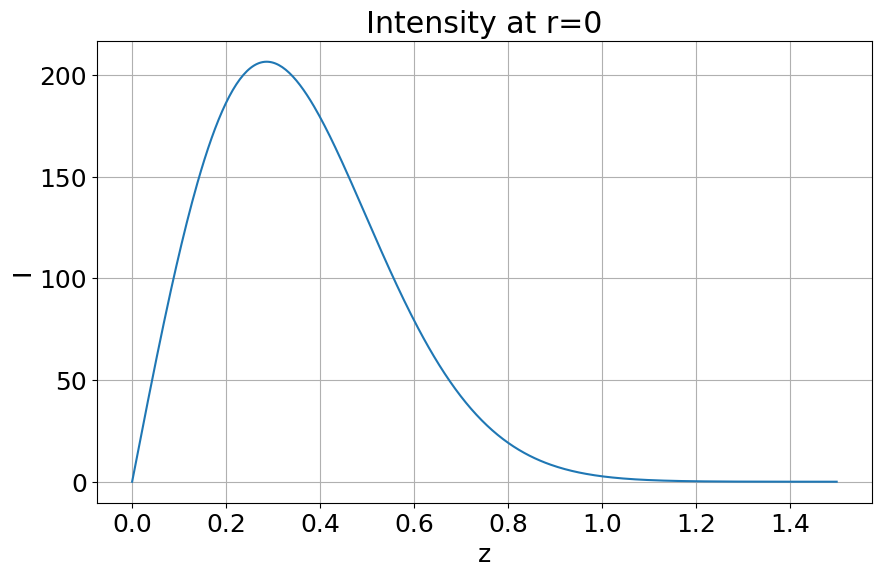

In [3]:
wl=632.8e-9  # wavelength
k= 2*np.pi/wl   # wavenumber
alpha=degtorad(1)
gamma = calc_gamma(alpha)  
w0 = 0.005  # beam waist
I0 = 1  # peak intensity

z_values = np.linspace(0, 1.5, 400)
r_values = np.linspace(0, 1 , 500)
I_values = I(r_values, z_values, k, alpha, gamma, I0, w0)

#Plot r=0

plt.figure(figsize=(10, 6))
plt.plot(z_values, I_values[0, :])
plt.xlabel('z')
plt.ylabel('I')
plt.grid(True)

plt.title('Intensity at r=0')
plt.show()

0.013094789836021463


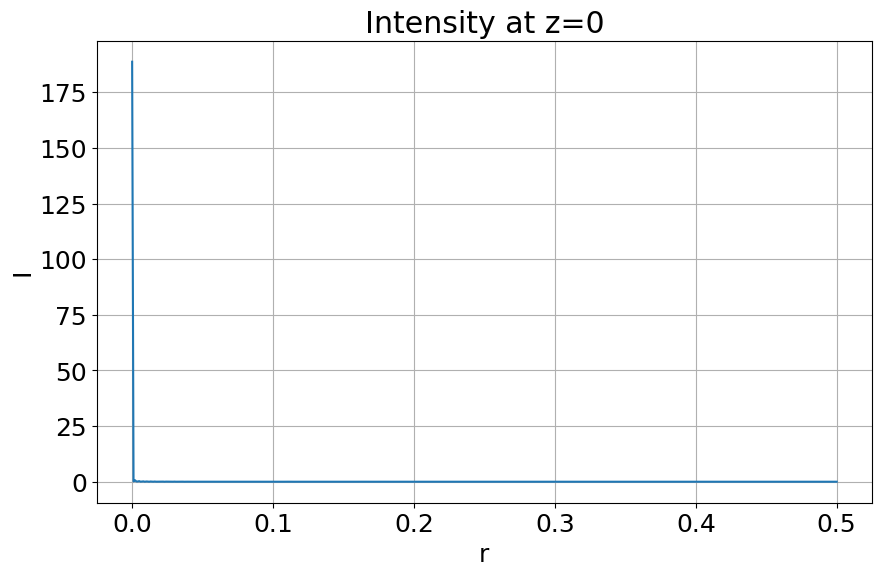

In [4]:
wl=632.8e-9  # wavelength
k= 2*np.pi/wl   # wavenumber
alpha=degtorad(1)
gamma = calc_gamma(alpha)  
w0 = 0.005  # beam waist
I0 = 1  # peak intensity

z_values = np.linspace(0, 1.5, 400)
r_values = np.linspace(0, 0.5, 500)
I_values = I(r_values, z_values, k, alpha, gamma, I0, w0)

#Plot z=0

plt.figure(figsize=(10, 6))
plt.plot(r_values, I_values[:,100])
plt.xlabel('r')
plt.ylabel('I')
plt.grid(True)

plt.title('Intensity at z=0')
plt.show()

5.08
2.6189579672042926


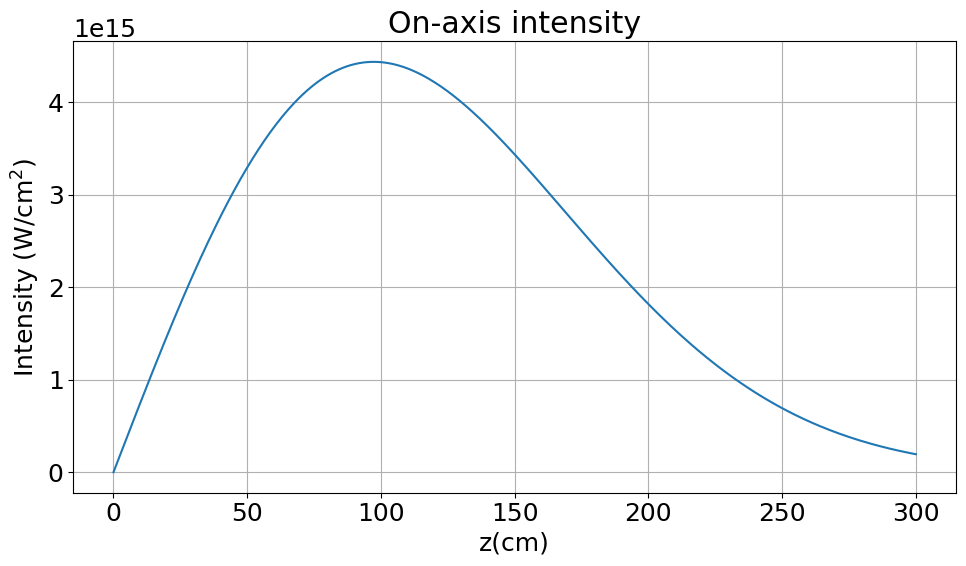

In [5]:
wl=800e-7  # wavelength
k= 2*np.pi/wl   # wavenumber
alpha=degtorad(1)
gamma = calc_gamma(alpha)  
w0 = fwhm_to_sigma(2)  # beam waist
I0 = 8e12  # peak intensity
in_to_cm=2.54
rmax=2*in_to_cm
print(rmax)

z_values = np.linspace(0, 300, 400)
r_values = np.linspace(0, rmax, 500)
I_values = I(r_values, z_values, k, alpha, gamma, I0, w0)

#Plot r=0

plt.figure(figsize=(10, 6))
plt.plot(z_values, I_values[0, :])
plt.xlabel('z(cm)')
plt.ylabel(r'Intensity (W/cm$^2$)')
plt.grid(True)

plt.title('On-axis intensity')
plt.tight_layout()
plt.savefig('on_axis_intensity-msp.png')
plt.show()

-0.0


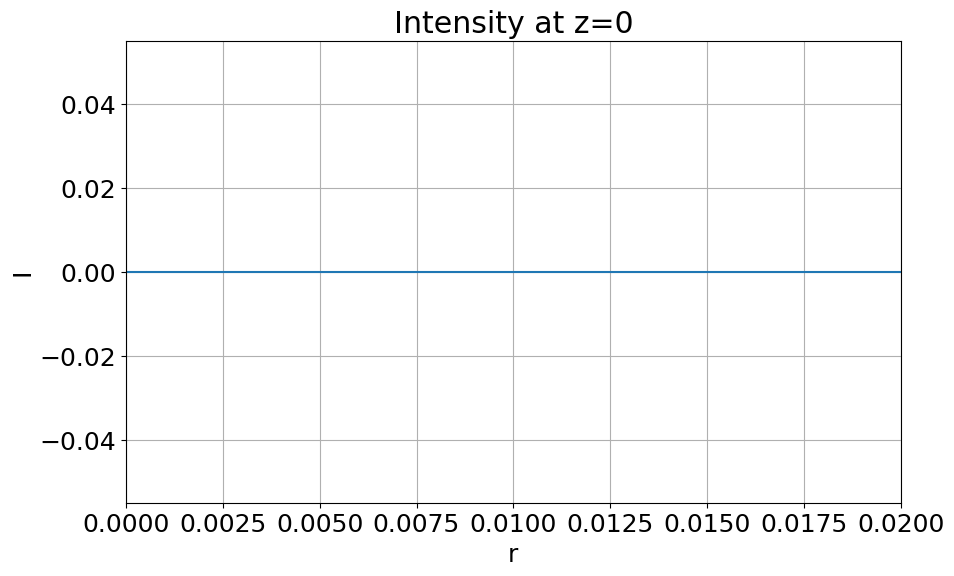

In [6]:
wl=800e-7  # wavelength
k= 2*np.pi/wl   # wavenumber
alpha=degtorad(1)
gamma = calc_gamma(1.5, alpha)  
w0 = fwhm_to_sigma(2)  # beam waist
I0 = 5e14  # peak intensity
in_to_cm=2.54
rmax=2*in_to_cm

z_values = np.linspace(0, 300, 400)
r_values = np.linspace(0, rmax, 500)
I_values = I(r_values, z_values, k, alpha, gamma, I0, w0)

#Plot r=0

plt.figure(figsize=(10, 6))
plt.plot(r_values, I_values[:,300])
plt.xlabel('r')
plt.ylabel('I')
plt.grid(True)
plt.xlim([0,0.02])
plt.title('Intensity at z=0')
plt.show()